# Tahap9 — kontribusi antarstasiun

Target asli Way Urang, horizon30menit, empat fold tahap6. S0=C30WayUrang; S1 tambahPulomerak; S2 tambahTalang; S3 keduanya. HanyaSO2 donor, offsetorigin1/2/3/7/13/25/49 dan missingasli; usia hanya diagnostik. Clock sebanding dan delay30menit adalah asumsi belum terverifikasi. Tidak melatih DL, tuning, atau membuka nilai test akhir. Semua hasil lama dipertahankan.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from interstation_stage9 import Experiment
from IPython.display import display,Markdown,Image
import pandas as pd
e=Experiment().prepare()
print('Config pra-fit SHA256:',e.config_hash)
display(pd.DataFrame(e.cfg['folds']))
display(pd.DataFrame(e.source_checks))
display(pd.DataFrame(e.offgrid))
print('Fitur donor offsets:',e.cfg['donor_origin_offsets'])


Rancangan terkunci sebelum fit: a4f323b413cf588de32669eef014c4a43a8580286f3ae8835cb5b2d5b0bbbcf8
Config pra-fit SHA256: a4f323b413cf588de32669eef014c4a43a8580286f3ae8835cb5b2d5b0bbbcf8
Fitur donor offsets: [1, 2, 3, 7, 13, 25, 49]


,Fold,Train mulai,Train akhir,Validasi mulai,Validasi akhir,Validasi akhir eksklusif,Slot train,Slot validasi,Durasi validasi jam,Index awal validasi,Index akhir validasi eksklusif
0,Fold_01,2025-01-01 00:00:00,2025-04-30 23:30:00,2025-05-01 00:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,5760,4972,2486.0,5760,10732
1,Fold_02,2025-01-01 00:00:00,2025-08-12 13:30:00,2025-08-12 14:00:00,2025-11-24 03:00:00,2025-11-24 03:30:00,10732,4971,2485.5,10732,15703
2,Fold_03,2025-01-01 00:00:00,2025-11-24 03:00:00,2025-11-24 03:30:00,2026-03-07 16:30:00,2026-03-07 17:00:00,15703,4971,2485.5,15703,20674
3,Fold_04,2025-01-01 00:00:00,2026-03-07 16:30:00,2026-03-07 17:00:00,2026-06-19 06:00:00,2026-06-19 06:30:00,20674,4971,2485.5,20674,25645


,Stasiun,Sheet,Satuan literal,Slot development,Baris sumber sebelum test,Nilai numerik grid cocok sumber,Offgrid baris,Offgrid SO2 numerik nonkosong
0,Way Urang,Kab. Lampung Selatan Way Urang,µg/m³,25645,25441,True,1,0
1,Pulomerak,Kota Cilegon Pulomerak,µg/m³,25645,25444,True,2,0
2,Talang,Bandar Lampung Talang,µg/m³,25645,23655,True,0,0


,Stasiun,Baris Excel,Timestamp,Timestamp literal,SO2 literal,SO2 numerik,On grid
0,Way Urang,6624,2025-05-22 19:01:00,2025-05-22 19:01:00,NaN,NaN,False
1,Pulomerak,4394,2025-04-05 12:01:00,2025-04-05 12:01:00,NaN,NaN,False
2,Pulomerak,4396,2025-04-05 14:01:00,2025-04-05 14:01:00,NaN,NaN,False


## Kausalitas dan irisan sebelum model

MedianC30 pada tiapseri sendiri, prefix30hari hanya masa lalu. Donorfreeze[:a−1] agar statistik tersedia pada origin evaluasi pertama; Wayfreeze[:a] persisC30 lama. S0buffer48slot, donorbuffer49. Train semua skenario dan targetasli sama; tidak ada donor untuk target. S0 di-fit ulang. Laporkan jumlah/distribusi yang tersisih sebelum menafsirkan skor.

In [2]:
e.prepare_all()
display(pd.DataFrame([f.gate for f in e.folds]))
display(pd.DataFrame([r for f in e.folds for r in f.flow]))
display(pd.DataFrame([r for f in e.folds for r in f.dist]))
display(pd.DataFrame([r for f in e.folds for r in f.lost]))
print('Fitcount sebelum semua gate:',e.fit_count)


Gate sebelum semua model: {'Fold': 'Fold_01', 'Fit count sebelum gate': 0, 'Train bersama': 3539, 'Evaluasi bersama': 4890, 'Minimum train komputasional': 620, 'S0 train layak mandiri': 3539, 'S0 hilang akibat irisan': 0, 'Lulus': True, 'S0 fitur identik C30 lama': True}
Gate sebelum semua model: {'Fold': 'Fold_02', 'Fit count sebelum gate': 0, 'Train bersama': 8429, 'Evaluasi bersama': 4969, 'Minimum train komputasional': 620, 'S0 train layak mandiri': 8429, 'S0 hilang akibat irisan': 0, 'Lulus': True, 'S0 fitur identik C30 lama': True}
Gate sebelum semua model: {'Fold': 'Fold_03', 'Fit count sebelum gate': 0, 'Train bersama': 13398, 'Evaluasi bersama': 4969, 'Minimum train komputasional': 620, 'S0 train layak mandiri': 13398, 'S0 hilang akibat irisan': 0, 'Lulus': True, 'S0 fitur identik C30 lama': True}
Gate sebelum semua model: {'Fold': 'Fold_04', 'Fit count sebelum gate': 0, 'Train bersama': 18367, 'Evaluasi bersama': 4969, 'Minimum train komputasional': 620, 'S0 train layak mandi

,Fold,Fit count sebelum gate,Train bersama,Evaluasi bersama,Minimum train komputasional,S0 train layak mandiri,S0 hilang akibat irisan,Lulus,S0 fitur identik C30 lama
0,Fold_01,0,3539,4890,620,3539,0,True,True
1,Fold_02,0,8429,4969,620,8429,0,True,True
2,Fold_03,0,13398,4969,620,13398,0,True,True
3,Fold_04,0,18367,4969,620,18367,0,True,True


,Fold,Bagian,Skenario,Kandidat setelah warmup buffer dasar purge,Target asli teramati,Buffer tambahan donor49 pada target teramati,Fitur nonfinite pada target teramati,Layak mandiri,Irisan digunakan,Keluar karena irisan
0,Fold_01,train,S0,4271,3539,0,0,3539,3539,0
1,Fold_01,train,S1,4271,3539,0,0,3539,3539,0
2,Fold_01,train,S2,4271,3539,0,0,3539,3539,0
3,Fold_01,train,S3,4271,3539,0,0,3539,3539,0
4,Fold_01,evaluation,S0,4972,4890,0,0,4890,4890,0
5,Fold_01,evaluation,S1,4972,4890,0,0,4890,4890,0
6,Fold_01,evaluation,S2,4972,4890,0,0,4890,4890,0
7,Fold_01,evaluation,S3,4972,4890,0,0,4890,4890,0
8,Fold_02,train,S0,9243,8429,0,0,8429,8429,0
9,Fold_02,train,S1,9243,8429,0,0,8429,8429,0


,Fold,Bagian,Domain,Awal target,Akhir target,Minimum,P1,P25,Median,P75,P99,Maksimum,N,Mean,SD,SO2 lebih2.14
0,Fold_01,train,target asli kandidat,2025-02-13 19:00:00,2025-04-30 23:30:00,1.24,1.33,44.42,45.24,45.82,77.3500,80.71,3539,38.468346,19.885072,2832
1,Fold_01,train,irisan digunakan,2025-02-13 19:00:00,2025-04-30 23:30:00,1.24,1.33,44.42,45.24,45.82,77.3500,80.71,3539,38.468346,19.885072,2832
2,Fold_01,evaluation,target asli kandidat,2025-05-01 00:00:00,2025-08-12 13:30:00,1.07,1.25,1.56,43.85,45.38,46.7411,47.81,4890,23.580558,21.929684,2456
3,Fold_01,evaluation,irisan digunakan,2025-05-01 00:00:00,2025-08-12 13:30:00,1.07,1.25,1.56,43.85,45.38,46.7411,47.81,4890,23.580558,21.929684,2456
4,Fold_02,train,target asli kandidat,2025-02-13 19:00:00,2025-08-12 13:30:00,1.07,1.30,1.58,44.91,45.61,75.9260,80.71,8429,29.831345,22.337377,5288
5,Fold_02,train,irisan digunakan,2025-02-13 19:00:00,2025-08-12 13:30:00,1.07,1.30,1.58,44.91,45.61,75.9260,80.71,8429,29.831345,22.337377,5288
6,Fold_02,evaluation,target asli kandidat,2025-08-12 14:00:00,2025-11-24 03:00:00,1.04,1.19,1.48,1.56,1.64,1.9132,2.14,4969,1.560920,0.131798,0
7,Fold_02,evaluation,irisan digunakan,2025-08-12 14:00:00,2025-11-24 03:00:00,1.04,1.19,1.48,1.56,1.64,1.9132,2.14,4969,1.560920,0.131798,0
8,Fold_03,train,target asli kandidat,2025-02-13 19:00:00,2025-11-24 03:00:00,1.04,1.24,1.52,1.66,45.20,75.0100,80.71,13398,19.346516,22.369445,5288
9,Fold_03,train,irisan digunakan,2025-02-13 19:00:00,2025-11-24 03:00:00,1.04,1.24,1.52,1.66,45.20,75.0100,80.71,13398,19.346516,22.369445,5288


,Fold,Bagian,Skenario,N,Minimum,P1,P25,Median,P75,P99,Maksimum,Mean,SD,SO2 lebih2.14
0,Fold_01,train,S0,0,None,None,None,None,None,None,None,None,None,0
1,Fold_01,train,S1,0,None,None,None,None,None,None,None,None,None,0
2,Fold_01,train,S2,0,None,None,None,None,None,None,None,None,None,0
3,Fold_01,train,S3,0,None,None,None,None,None,None,None,None,None,0
4,Fold_01,evaluation,S0,0,None,None,None,None,None,None,None,None,None,0
5,Fold_01,evaluation,S1,0,None,None,None,None,None,None,None,None,None,0
6,Fold_01,evaluation,S2,0,None,None,None,None,None,None,None,None,None,0
7,Fold_01,evaluation,S3,0,None,None,None,None,None,None,None,None,None,0
8,Fold_02,train,S0,0,None,None,None,None,None,None,None,None,None,0
9,Fold_02,train,S1,0,None,None,None,None,None,None,None,None,None,0


## Ridge tetap dan evaluasi

16Ridge baru, alpha1/intercept/SVD sama; StandardScaler hanya trainbersama foldterkait, targettidak diskalakan. Semua targetevaluasi asli; persistence dari originalWay terakhir≤origin. Cakupanmandiri danbersama terpisah. Persentaseperbaikan=100×(errorS0−errorscenario)/errorS0. Tidak mengubah split/fold/fitur sesudah melihat skor.

,Fold,Skenario,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Fold_01,S0,mandiri,4890,4890,100.0,17.245739,40.229392,-11.924223,1317,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
1,Fold_01,S0,bersama,4890,4890,100.0,17.245739,40.229392,-11.924223,1317,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
2,Fold_01,S1,mandiri,4890,4890,100.0,17.347303,40.464950,-11.970927,1311,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
3,Fold_01,S1,bersama,4890,4890,100.0,17.347303,40.464950,-11.970927,1311,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
4,Fold_01,S2,mandiri,4890,4890,100.0,17.304925,40.742816,-12.343746,1304,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
5,Fold_01,S2,bersama,4890,4890,100.0,17.304925,40.742816,-12.343746,1304,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
6,Fold_01,S3,mandiri,4890,4890,100.0,17.450968,41.099373,-12.436822,1299,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
7,Fold_01,S3,bersama,4890,4890,100.0,17.450968,41.099373,-12.436822,1299,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
8,Fold_01,Persistence,mandiri,4890,4890,100.0,0.430562,0.885256,0.009049,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...
9,Fold_01,Persistence,bersama,4890,4890,100.0,0.430562,0.885256,0.009049,0,2a6708180361da393dc963ce8cc2366dd4837d308b8a5b...


,Fold,Skenario,Domain,N,Denominator target asli,Cakupan persen,MAE,RMSE,Bias,Prediksi negatif,SHA256 timestamp
0,Gabungan_OOF,S0,mandiri,19797,19797,100.0,4.370998,19.996605,-2.982118,1321,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
1,Gabungan_OOF,S0,bersama,19797,19797,100.0,4.370998,19.996605,-2.982118,1321,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
2,Gabungan_OOF,S1,mandiri,19797,19797,100.0,4.400311,20.113696,-2.972787,1315,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
3,Gabungan_OOF,S1,bersama,19797,19797,100.0,4.400311,20.113696,-2.972787,1315,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
4,Gabungan_OOF,S2,mandiri,19797,19797,100.0,4.392604,20.251823,-3.082305,1308,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
5,Gabungan_OOF,S2,bersama,19797,19797,100.0,4.392604,20.251823,-3.082305,1308,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
6,Gabungan_OOF,S3,mandiri,19797,19797,100.0,4.434799,20.429058,-3.077127,1303,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
7,Gabungan_OOF,S3,bersama,19797,19797,100.0,4.434799,20.429058,-3.077127,1303,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
8,Gabungan_OOF,Persistence,mandiri,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...
9,Gabungan_OOF,Persistence,bersama,19797,19797,100.0,0.206335,0.464340,0.002240,0,1663821d30ee4523fd8c636c175f3570cf6976594a170f...


,Fold,Skenario,N identik,Delta MAE vs S0,Delta RMSE vs S0,Perbaikan MAE persen,Perbaikan RMSE persen,Delta MAE vs persistence,Delta RMSE vs persistence
0,Fold_01,S0,4890,0.000000,0.000000,0.000000,0.000000,16.815177,39.344136
1,Fold_01,S1,4890,0.101564,0.235558,-0.588923,-0.585537,16.916741,39.579694
2,Fold_01,S2,4890,0.059186,0.513424,-0.343191,-1.276242,16.874362,39.857561
3,Fold_01,S3,4890,0.205228,0.869981,-1.190024,-2.162551,17.020405,40.214117
4,Fold_02,S0,4969,0.000000,0.000000,0.000000,0.000000,0.073193,0.424566
5,Fold_02,S1,4969,-0.000068,-0.000602,0.031484,0.098947,0.073125,0.423964
6,Fold_02,S2,4969,0.004953,0.000086,-2.291678,-0.014102,0.078146,0.424652
7,Fold_02,S3,4969,0.004704,-0.000772,-2.176255,0.126939,0.077897,0.423794
8,Fold_03,S0,4969,0.000000,0.000000,0.000000,0.000000,-0.016282,0.000468
9,Fold_03,S1,4969,0.012987,0.013434,-10.543564,-7.510030,-0.003295,0.013902


,Fold,S0 fitur identik C30 lama,S0 dilatih ulang,Train lama,Train bersama baru,Cohort identik,Maks selisih prediksi jika cohort sama
0,Fold_01,True,True,3539,3539,True,0.0
1,Fold_02,True,True,8429,8429,True,0.0
2,Fold_03,True,True,13398,13398,True,0.0
3,Fold_04,True,True,18367,18367,True,0.0


,Fold,Donor,Bagian sampel,N origin,Minimum menit grid,Median menit grid,P90 menit grid,P95 menit grid,P99 menit grid,Maksimum menit grid,Tanpa pengamatan asli grid,Minimum menit semua,Median menit semua,P90 menit semua,P95 menit semua,P99 menit semua,Maksimum menit semua,Tanpa pengamatan asli semua
0,Fold_01,Pulomerak,train,3539,30.0,30.0,5796.0,11103.0,15378.6,16440.0,0,30.0,30.0,5796.0,11103.0,15378.6,16440.0,0
1,Fold_01,Pulomerak,evaluation,4890,30.0,30.0,30.0,30.0,30.0,150.0,0,30.0,30.0,30.0,30.0,30.0,150.0,0
2,Fold_01,Talang,train,3539,30.0,30.0,2376.0,3270.0,4650.0,5580.0,0,30.0,30.0,2376.0,3270.0,4650.0,5580.0,0
3,Fold_01,Talang,evaluation,4890,30.0,30.0,30.0,30.0,1833.3,3300.0,0,30.0,30.0,30.0,30.0,1833.3,3300.0,0
4,Fold_02,Pulomerak,train,8429,30.0,30.0,30.0,4098.0,13881.6,16440.0,0,30.0,30.0,30.0,4098.0,13881.6,16440.0,0
5,Fold_02,Pulomerak,evaluation,4969,30.0,30.0,30.0,30.0,30.0,90.0,0,30.0,30.0,30.0,30.0,30.0,90.0,0
6,Fold_02,Talang,train,8429,30.0,30.0,810.0,2250.0,3930.0,5580.0,0,30.0,30.0,810.0,2250.0,3930.0,5580.0,0
7,Fold_02,Talang,evaluation,4969,30.0,30.0,30.0,30.0,30.0,30.0,0,30.0,30.0,30.0,30.0,30.0,30.0,0
8,Fold_03,Pulomerak,train,13398,30.0,30.0,30.0,360.0,12390.9,16440.0,0,30.0,30.0,30.0,360.0,12390.9,16440.0,0
9,Fold_03,Pulomerak,evaluation,4969,30.0,30.0,15516.0,22998.0,28959.6,30450.0,0,30.0,30.0,15516.0,22998.0,28959.6,30450.0,0


,Fold,Donor,Bagian sampel model,Jumlah rentetan terkait,Run terpanjang slot,Durasi run terpanjang menit,Timestamp sumber konstan unik digunakan
0,Fold_01,Pulomerak,train,6,1362,40860,1564
1,Fold_01,Pulomerak,evaluation,46,387,11610,1232
2,Fold_01,Talang,train,511,35,1050,1692
3,Fold_01,Talang,evaluation,881,119,3570,2292
4,Fold_02,Pulomerak,train,52,1362,40860,2796
5,Fold_02,Pulomerak,evaluation,45,3,90,92
6,Fold_02,Talang,train,1386,119,3570,3972
7,Fold_02,Talang,evaluation,367,3190,95700,3689
8,Fold_03,Pulomerak,train,97,1362,40860,2888
9,Fold_03,Pulomerak,evaluation,37,849,25470,1775


,File,SHA256 sebelum,SHA256 sesudah,Identik
0,.gitattributes,442b6d5b9132ea1d7543873d490b995572ad625ebcd6bc...,442b6d5b9132ea1d7543873d490b995572ad625ebcd6bc...,True
1,.gitignore,d177f3cfed2a5f724a80e72f9e467bb796ff1df075a8c3...,d177f3cfed2a5f724a80e72f9e467bb796ff1df075a8c3...,True
2,README.md,65b32244cdd8c53c790fa04c98cd2a2d63d9152bc07074...,65b32244cdd8c53c790fa04c98cd2a2d63d9152bc07074...,True
3,data_raw/Telkom University Purwokerto - Intan ...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,True
4,notebooks/01_audit_data.ipynb,5870504f9d16d342161cd82ba14b554e21aee5604df47b...,5870504f9d16d342161cd82ba14b554e21aee5604df47b...,True
...,...,...,...,...
1184,scripts/write_forecast_report.py,33c46455e7c055bb8ed238133a5e60505bc7ebda1513ee...,33c46455e7c055bb8ed238133a5e60505bc7ebda1513ee...,True
1185,scripts/write_lstm_stage7.py,26dc17d924896d9a3e026d0448f876af9439b80c6202b5...,26dc17d924896d9a3e026d0448f876af9439b80c6202b5...,True
1186,scripts/write_pilot_report.py,0c95bd208bb3d034494104792994792a6385208723355b...,0c95bd208bb3d034494104792994792a6385208723355b...,True
1187,scripts/write_preprocessing_design.py,38f0c0dc50482511373c406cc7744c5f88aa97d6478466...,38f0c0dc50482511373c406cc7744c5f88aa97d6478466...,True


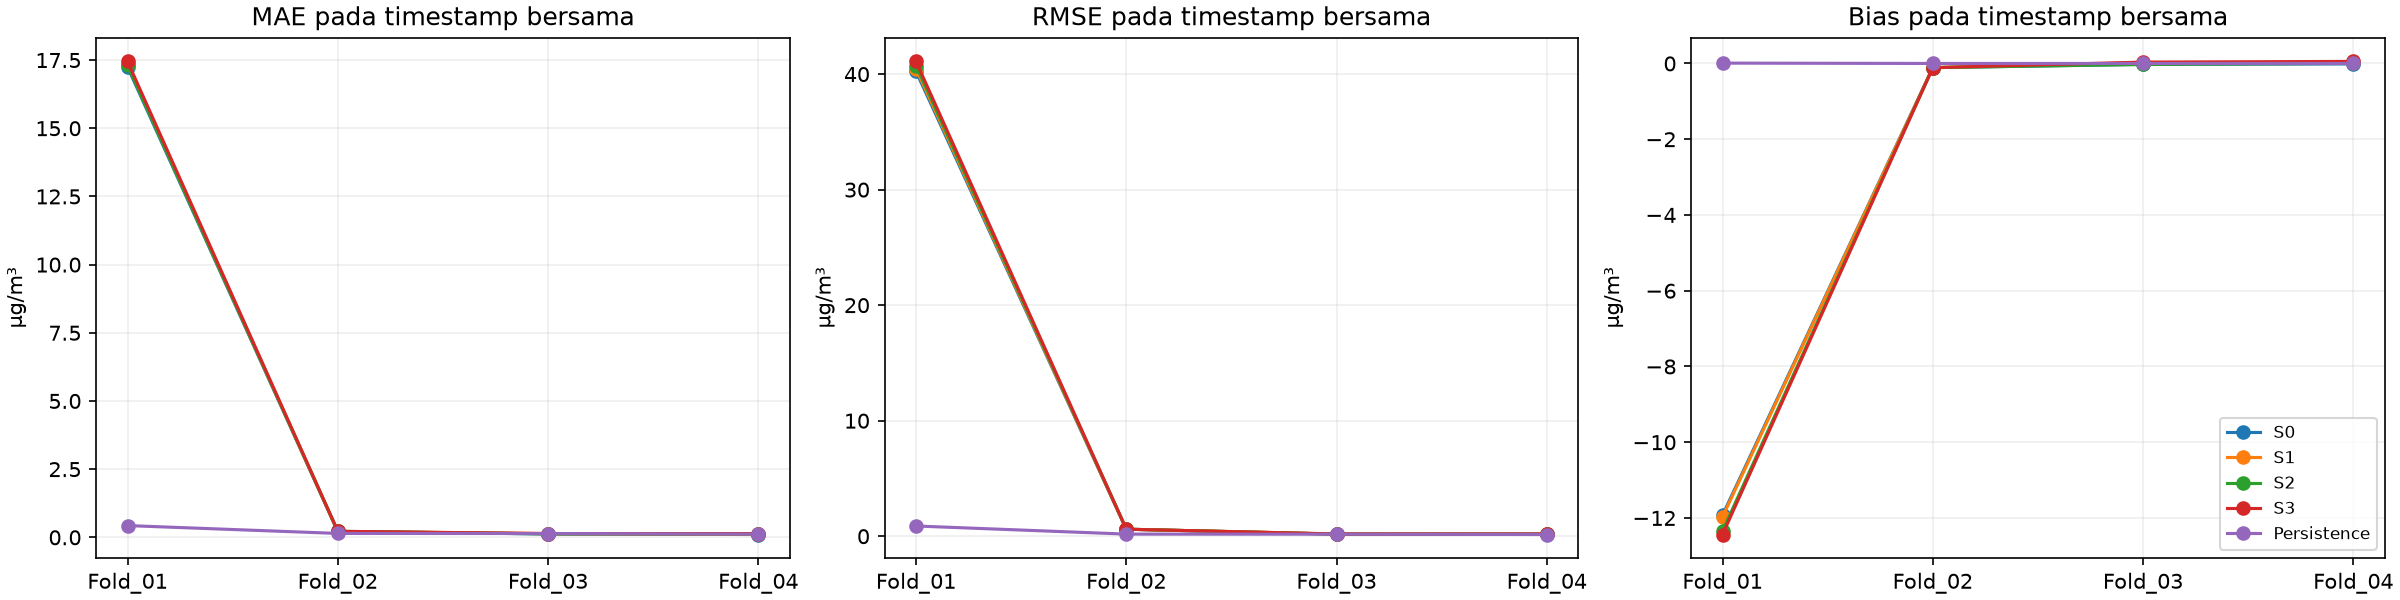

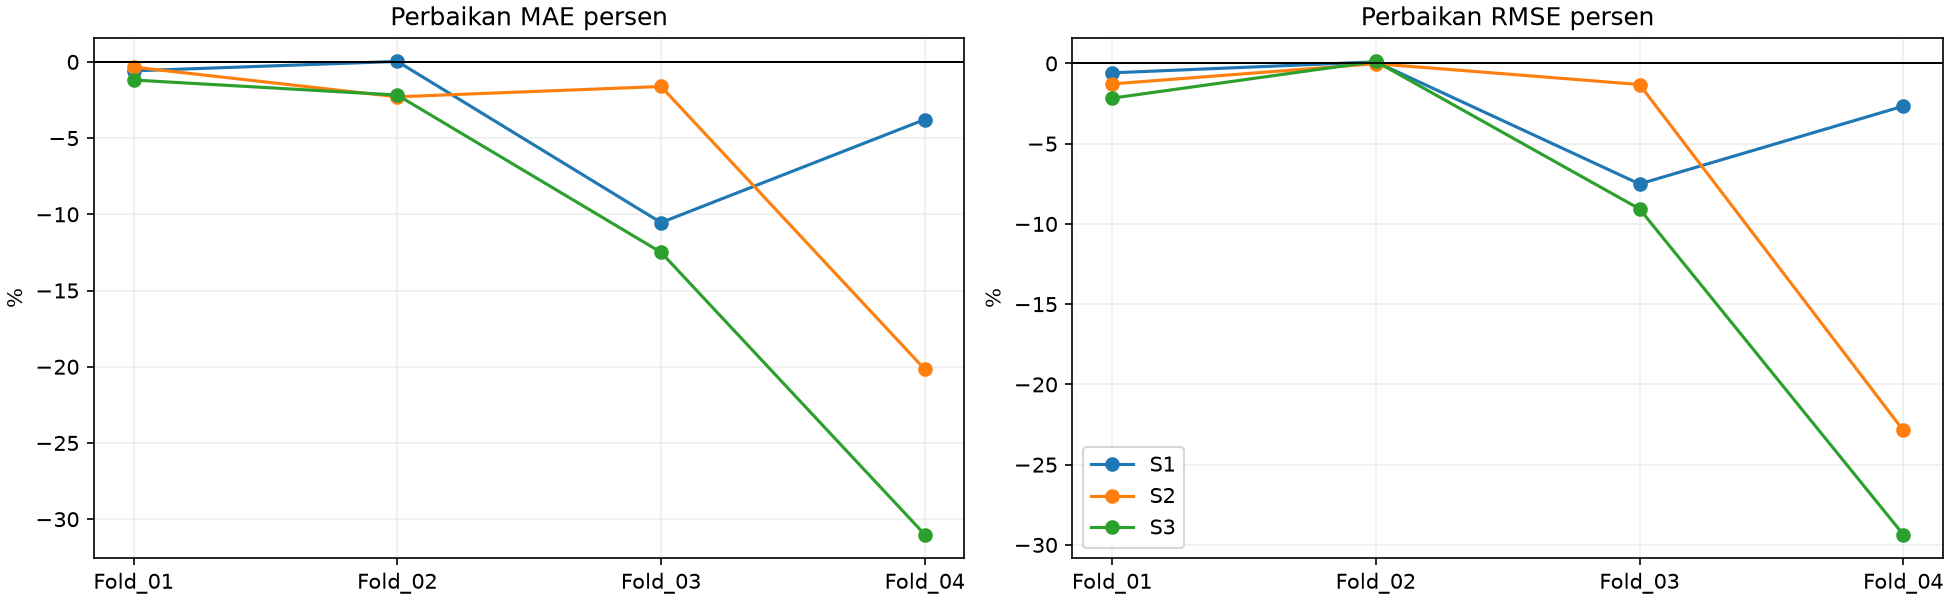

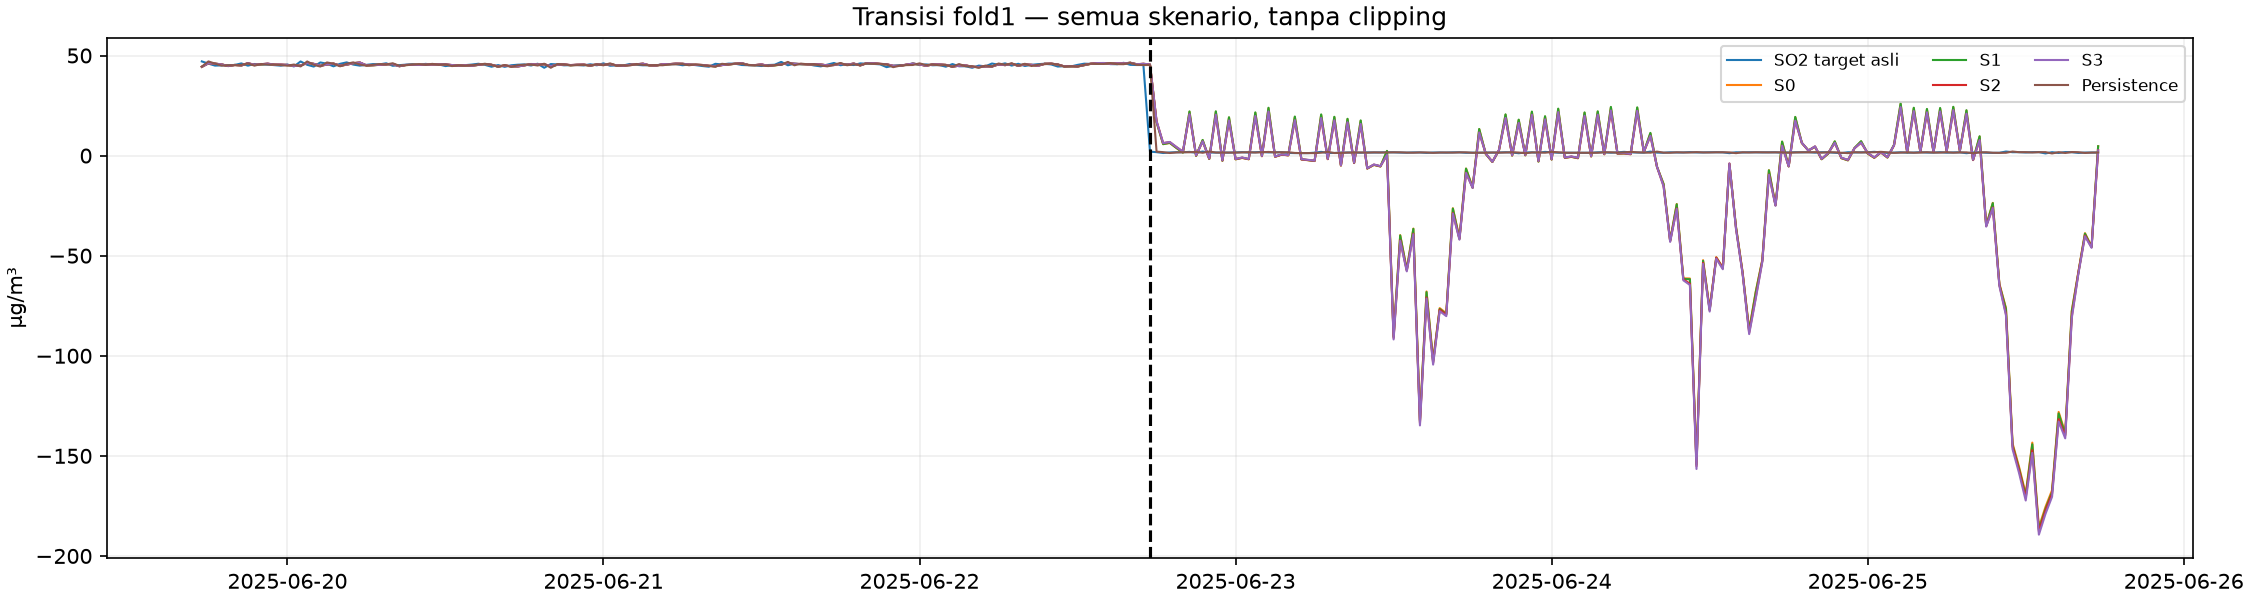

In [3]:
e.train()
display(pd.DataFrame(e.metrics))
display(pd.DataFrame(e.pooled))
display(pd.DataFrame(e.deltas))
display(pd.DataFrame(e.s0_audit))
display(pd.DataFrame(e.age_stats))
display(pd.DataFrame(e.constant_summary))
display(pd.DataFrame(e.integrity))
for name in ['skor_per_fold.png','perubahan_vs_S0.png','transisi_22_juni.png']:
    display(Image(filename=str(ROOT/'outputs/figures/kontribusi_antarstasiun'/name)))


In [4]:
e.export_excel()
display(Markdown((ROOT/'outputs/ringkasan_kontribusi_antarstasiun.md').read_text(encoding='utf-8')))


{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Fold","Skenario","Domain","N","Denominator target asli","Cakupan persen"],["Gabungan_OOF","S0","mandiri",19797,19797,100],["Gabungan_OOF","S0","bersama",19797,19797,100],["Gabungan_OOF","S1","mandiri",19797,19797,100]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\hasil_kontribusi_antarstasiun.xlsx.inspect.ndjson
Ekspor selesai: 28 sheet.



# Tahap 9 — kontribusi antarstasiun untuk SO₂ Way Urang

**Target seluruh skenario adalah SO₂ Way Urang asli, horizon 30 menit.** Development set train+validasi lama sudah dipakai dalam eksperimen sebelumnya; ini validasi pengembangan, bukan holdout independen. Test akhir mulai2026-06-19 06:30 tidak dimuat nilainya atau dievaluasi. Tidak melatih deep learning atau melakukan tuning.

## Rancangan dikunci sebelum training

Konfigurasi disimpan sebelum estimasi median/scaler dan 16 fit Ridge; SHA256: a4f323b413cf588de32669eef014c4a43a8580286f3ae8835cb5b2d5b0bbbcf8. Keempat gate dihitung saat fit count=0. Median dan warmup30 hari adalah pilihan operasional sementara, bukan metode terbukti paling akurat.

| Skenario | Masukan donor | Jumlah fitur |
|---|---|---|
| S0 | tidak ada; Way Urang saja | 34 |
| S1 | Pulomerak | 48 |
| S2 | Talang | 48 |
| S3 | Pulomerak, Talang | 62 |

| Fold | Train mulai | Train akhir | Validasi mulai | Validasi akhir |
|---|---|---|---|---|
| Fold_01 | 2025-01-01 00:00:00 | 2025-04-30 23:30:00 | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 |
| Fold_02 | 2025-01-01 00:00:00 | 2025-08-12 13:30:00 | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 |
| Fold_03 | 2025-01-01 00:00:00 | 2025-11-24 03:00:00 | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 |
| Fold_04 | 2025-01-01 00:00:00 | 2026-03-07 16:30:00 | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 |

S0 memakai persis 34 fitur C30 tanpa Curah Hujan: SO₂ lag0/1/2/6/12/24/48,10 kovariat Way Urang lag1 dan 17 indikator missing asli. Tidak ada meteorologi donor. Ridge alpha 1, fit_intercept=True, solver SVD, StandardScaler seluruh kolom fit di timestamp train bersama, CPU 1 thread. Target tidak diskalakan atau diisi. S0 dilatih ulang, bukan mengambil skor lama.

Donor terbaru adalah origin−1 slot; lag0/1/2/6/12/24/48 relatif waktu itu menghasilkan offset **1/2/3/7/13/25/49 slot sebelum origin**. Tiap donor menyumbang7nilaiSO₂ dan7 indikator missing asli. Tidak ada informasi donor sesudah origin−30menit. Usia donor hanya diagnostik, tidak menjadi fitur. Daftar kolom per skenario ada pada `Fold_*/nama_fitur.json`.

## Penyelarasan, sumber dan asumsi

| Stasiun | Sheet | Satuan literal | Slot development | Baris sumber sebelum test | Nilai numerik grid cocok sumber | Offgrid baris | Offgrid SO2 numerik nonkosong |
|---|---|---|---|---|---|---|---|
| Way Urang | Kab. Lampung Selatan Way Urang | µg/m³ | 25645 | 25441 | True | 1 | 0 |
| Pulomerak | Kota Cilegon Pulomerak | µg/m³ | 25645 | 25444 | True | 2 | 0 |
| Talang | Bandar Lampung Talang | µg/m³ | 25645 | 23655 | True | 0 | 0 |

Tiga stasiun tetap menjadi seri terpisah; penyelarasan menggunakan timestamp persis 00/30 pada grid Way Urang. Clock tertulis dianggap sebanding, tanpa konversi zona atau penetapan zona waktu. Penundaan30menit adalah asumsi eksperimen, **bukan latensi operasional terverifikasi**. Jika jam/latensi sebenarnya berbeda, manfaat donor dapat berubah.

Grid audit historis dibaca hanya 25.645 slot development. Untuk verifikasi sumber, timestamp Excel dibaca sendiri hingga batas test; kolom SO₂ dibaca hanya sampai baris sebelumnya. Tidak membaca nilaiSO₂ test. Nilai grid dibandingkan langsung dengan sumber; fileExcel dibuka read_only tanpa save.

| Stasiun | Baris Excel | Timestamp | SO2 literal | SO2 numerik | On grid |
|---|---|---|---|---|---|
| Way Urang | 6624 | 2025-05-22 19:01:00 | — | — | False |
| Pulomerak | 4394 | 2025-04-05 12:01:00 | — | — | False |
| Pulomerak | 4396 | 2025-04-05 14:01:00 | — | — | False |

Ledger off-grid dipertahankan tanpa pembulatan. Pengamatan off-grid tidak masuk fitur grid atau median, tetapi jumlah/nilainya dilaporkan dan dapat masuk diagnostik usia “semua original” jika sudah tersedia sebelum cutoff. Tidak mengarang kode sensor atau sebab anomali.

| Stasiun | Slot development | N | Minimum | Median | Maksimum | Slot SO2 kosong/ambigu/nonnumerik | Nol | Negatif |
|---|---|---|---|---|---|---|---|---|
| Way Urang | 25645 | 23721 | 0.92 | 1.60 | 80.71 | 1924 | 0 | 0 |
| Pulomerak | 25645 | 22281 | 3.98 | 35.62 | 159.49 | 3364 | 0 | 0 |
| Talang | 25645 | 23641 | 18.00 | 65.00 | 173.00 | 2004 | 0 | 0 |

N berarti original numerik teramati, bukan otomatis valid menurut dokumentasi sensor. Baris hilang, sel kosong, ambigu/nonnumerik tetap ditandai. Nol, ekstrem dan konstanta tidak otomatis dihapus.

## Median, scaling dan batas kausal

Warmup1.440 slot dan pembaruan prefix1.440 slot tetap. Histori Way Urang diimputasi sebelum lag, menggunakan median raw prefix eksklusif awal query; statistik evaluasi beku raw Way[:a], a=indeks awalvalidasi. Ini identik C30 sebelumnya. Donor diimputasi **masing-masing dari serinya sendiri**; tidak memakai donor untuk mengisi target Way Urang.

Untuk donor, cutoff beku adalah raw donor[:a−1], sehingga timestamp sumber maksimum a−2 sudah tersedia pada origin evaluasi pertama a−1 menurut delay 1. Prefix train hanya mengandung masa lalu; query masa depan tidak menjadi donor statistik. Median yang belum tersedia tetap NaN, tanpa fallback. Tidak backwardfill atau interpolasi dua arah. Observasi asli baru yang sudah tersedia pada origin tetap boleh menjadi fitur historis.

S0 mempertahankan origin pertama 1.488; S1–S3 memakai 1.489 untuk tambahan lag donor 49. Train bersama memakai irisan seluruh skenario dengan target asli, lalu target yang melintasi validasi dipurge. StandardScaler dan Ridge tiap skenario diestimasi dari **timestamp train yang sama** dan hanya train fold terkait; tidak menggunakan parameter yang fit pada seluruh development.

## Kesetaraan sampel sebelum fit

| Fold | Train bersama | Evaluasi bersama | S0 train layak mandiri | S0 hilang akibat irisan | Lulus | Fit count sebelum gate |
|---|---|---|---|---|---|---|
| Fold_01 | 3539 | 4890 | 3539 | 0 | True | 0 |
| Fold_02 | 8429 | 4969 | 8429 | 0 | True | 0 |
| Fold_03 | 13398 | 4969 | 13398 | 0 | True | 0 |
| Fold_04 | 18367 | 4969 | 18367 | 0 | True | 0 |

| Fold | Bagian | Skenario | Kandidat setelah warmup buffer dasar purge | Target asli teramati | Buffer tambahan donor49 pada target teramati | Fitur nonfinite pada target teramati | Layak mandiri | Irisan digunakan | Keluar karena irisan |
|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | train | S0 | 4271 | 3539 | 0 | 0 | 3539 | 3539 | 0 |
| Fold_01 | train | S1 | 4271 | 3539 | 0 | 0 | 3539 | 3539 | 0 |
| Fold_01 | train | S2 | 4271 | 3539 | 0 | 0 | 3539 | 3539 | 0 |
| Fold_01 | train | S3 | 4271 | 3539 | 0 | 0 | 3539 | 3539 | 0 |
| Fold_01 | evaluation | S0 | 4972 | 4890 | 0 | 0 | 4890 | 4890 | 0 |
| Fold_01 | evaluation | S1 | 4972 | 4890 | 0 | 0 | 4890 | 4890 | 0 |
| Fold_01 | evaluation | S2 | 4972 | 4890 | 0 | 0 | 4890 | 4890 | 0 |
| Fold_01 | evaluation | S3 | 4972 | 4890 | 0 | 0 | 4890 | 4890 | 0 |
| Fold_02 | train | S0 | 9243 | 8429 | 0 | 0 | 8429 | 8429 | 0 |
| Fold_02 | train | S1 | 9243 | 8429 | 0 | 0 | 8429 | 8429 | 0 |
| Fold_02 | train | S2 | 9243 | 8429 | 0 | 0 | 8429 | 8429 | 0 |
| Fold_02 | train | S3 | 9243 | 8429 | 0 | 0 | 8429 | 8429 | 0 |
| Fold_02 | evaluation | S0 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_02 | evaluation | S1 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_02 | evaluation | S2 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_02 | evaluation | S3 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_03 | train | S0 | 14214 | 13398 | 0 | 0 | 13398 | 13398 | 0 |
| Fold_03 | train | S1 | 14214 | 13398 | 0 | 0 | 13398 | 13398 | 0 |
| Fold_03 | train | S2 | 14214 | 13398 | 0 | 0 | 13398 | 13398 | 0 |
| Fold_03 | train | S3 | 14214 | 13398 | 0 | 0 | 13398 | 13398 | 0 |
| Fold_03 | evaluation | S0 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_03 | evaluation | S1 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_03 | evaluation | S2 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_03 | evaluation | S3 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_04 | train | S0 | 19185 | 18367 | 0 | 0 | 18367 | 18367 | 0 |
| Fold_04 | train | S1 | 19185 | 18367 | 0 | 0 | 18367 | 18367 | 0 |
| Fold_04 | train | S2 | 19185 | 18367 | 0 | 0 | 18367 | 18367 | 0 |
| Fold_04 | train | S3 | 19185 | 18367 | 0 | 0 | 18367 | 18367 | 0 |
| Fold_04 | evaluation | S0 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_04 | evaluation | S1 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_04 | evaluation | S2 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |
| Fold_04 | evaluation | S3 | 4971 | 4969 | 0 | 0 | 4969 | 4969 | 0 |

| Fold | Bagian | Awal target | Akhir target | N | Minimum | P25 | Median | P75 | Maksimum | Mean | SD |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | train | 2025-02-13 19:00:00 | 2025-04-30 23:30:00 | 3539 | 1.24 | 44.42 | 45.24 | 45.82 | 80.71 | 38.47 | 19.89 |
| Fold_01 | evaluation | 2025-05-01 00:00:00 | 2025-08-12 13:30:00 | 4890 | 1.07 | 1.56 | 43.85 | 45.38 | 47.81 | 23.58 | 21.93 |
| Fold_02 | train | 2025-02-13 19:00:00 | 2025-08-12 13:30:00 | 8429 | 1.07 | 1.58 | 44.91 | 45.61 | 80.71 | 29.83 | 22.34 |
| Fold_02 | evaluation | 2025-08-12 14:00:00 | 2025-11-24 03:00:00 | 4969 | 1.04 | 1.48 | 1.56 | 1.64 | 2.14 | 1.56 | 0.13 |
| Fold_03 | train | 2025-02-13 19:00:00 | 2025-11-24 03:00:00 | 13398 | 1.04 | 1.52 | 1.66 | 45.20 | 80.71 | 19.35 | 22.37 |
| Fold_03 | evaluation | 2025-11-24 03:30:00 | 2026-03-07 16:30:00 | 4969 | 1.08 | 1.49 | 1.56 | 1.63 | 2.04 | 1.56 | 0.13 |
| Fold_04 | train | 2025-02-13 19:00:00 | 2026-03-07 16:30:00 | 18367 | 1.04 | 1.51 | 1.61 | 44.71 | 80.71 | 14.54 | 20.67 |
| Fold_04 | evaluation | 2026-03-07 17:00:00 | 2026-06-19 06:00:00 | 4969 | 1.09 | 1.49 | 1.56 | 1.63 | 2.06 | 1.56 | 0.11 |

Target yang tersisih semata karena irisan setelah layak mandiri:

| Fold | Bagian | Skenario | N | Minimum | Median | Maksimum |
|---|---|---|---|---|---|---|
| Fold_01 | train | S0 | 0 | — | — | — |
| Fold_01 | train | S1 | 0 | — | — | — |
| Fold_01 | train | S2 | 0 | — | — | — |
| Fold_01 | train | S3 | 0 | — | — | — |
| Fold_01 | evaluation | S0 | 0 | — | — | — |
| Fold_01 | evaluation | S1 | 0 | — | — | — |
| Fold_01 | evaluation | S2 | 0 | — | — | — |
| Fold_01 | evaluation | S3 | 0 | — | — | — |
| Fold_02 | train | S0 | 0 | — | — | — |
| Fold_02 | train | S1 | 0 | — | — | — |
| Fold_02 | train | S2 | 0 | — | — | — |
| Fold_02 | train | S3 | 0 | — | — | — |
| Fold_02 | evaluation | S0 | 0 | — | — | — |
| Fold_02 | evaluation | S1 | 0 | — | — | — |
| Fold_02 | evaluation | S2 | 0 | — | — | — |
| Fold_02 | evaluation | S3 | 0 | — | — | — |
| Fold_03 | train | S0 | 0 | — | — | — |
| Fold_03 | train | S1 | 0 | — | — | — |
| Fold_03 | train | S2 | 0 | — | — | — |
| Fold_03 | train | S3 | 0 | — | — | — |
| Fold_03 | evaluation | S0 | 0 | — | — | — |
| Fold_03 | evaluation | S1 | 0 | — | — | — |
| Fold_03 | evaluation | S2 | 0 | — | — | — |
| Fold_03 | evaluation | S3 | 0 | — | — | — |
| Fold_04 | train | S0 | 0 | — | — | — |
| Fold_04 | train | S1 | 0 | — | — | — |
| Fold_04 | train | S2 | 0 | — | — | — |
| Fold_04 | train | S3 | 0 | — | — | — |
| Fold_04 | evaluation | S0 | 0 | — | — | — |
| Fold_04 | evaluation | S1 | 0 | — | — | — |
| Fold_04 | evaluation | S2 | 0 | — | — | — |
| Fold_04 | evaluation | S3 | 0 | — | — | — |

Workbook memuat distribusi bulanan sebelum/sesudah irisan dan sampel keluar. Ledger CSV menyimpan setiap kandidat, kelayakan tiap skenario dan flag irisan tanpa menghapus grid. Hitungan buffer/nonfinite dapat tumpang tindih; jumlah layak dihitung dari mask gabungan, bukan penjumlahan penyebab. Apabila kehilangan besar atau komposisi berubah, manfaat hanya berlaku pada cohort terpilih dan tidak boleh digeneralisasi ke seluruh periode.

| Fold | S0 fitur identik C30 lama | S0 dilatih ulang | Train lama | Train bersama baru | Cohort identik | Maks selisih prediksi jika cohort sama |
|---|---|---|---|---|---|---|
| Fold_01 | True | True | 3539 | 3539 | True | 0.00 |
| Fold_02 | True | True | 8429 | 8429 | True | 0.00 |
| Fold_03 | True | True | 13398 | 13398 | True | 0.00 |
| Fold_04 | True | True | 18367 | 18367 | True | 0.00 |

## Skor pada timestamp identik

| Fold | Skenario | N | Denominator target asli | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | S0 | 4890 | 4890 | 100.000 | 17.245739 | 40.229392 | -11.924223 | 1317 |
| Fold_01 | S1 | 4890 | 4890 | 100.000 | 17.347303 | 40.464950 | -11.970927 | 1311 |
| Fold_01 | S2 | 4890 | 4890 | 100.000 | 17.304925 | 40.742816 | -12.343746 | 1304 |
| Fold_01 | S3 | 4890 | 4890 | 100.000 | 17.450968 | 41.099373 | -12.436822 | 1299 |
| Fold_01 | Persistence | 4890 | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 | 0 |
| Fold_02 | S0 | 4969 | 4969 | 100.000 | 0.216147 | 0.608248 | -0.110496 | 0 |
| Fold_02 | S1 | 4969 | 4969 | 100.000 | 0.216079 | 0.607646 | -0.113166 | 0 |
| Fold_02 | S2 | 4969 | 4969 | 100.000 | 0.221101 | 0.608334 | -0.109005 | 0 |
| Fold_02 | S3 | 4969 | 4969 | 100.000 | 0.220851 | 0.607476 | -0.110455 | 0 |
| Fold_02 | Persistence | 4969 | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 | 0 |
| Fold_03 | S0 | 4969 | 4969 | 100.000 | 0.123171 | 0.178886 | -0.023703 | 2 |
| Fold_03 | S1 | 4969 | 4969 | 100.000 | 0.136158 | 0.192320 | 0.022770 | 2 |
| Fold_03 | S2 | 4969 | 4969 | 100.000 | 0.125159 | 0.181233 | -0.026746 | 2 |
| Fold_03 | S3 | 4969 | 4969 | 100.000 | 0.138562 | 0.195100 | 0.035778 | 2 |
| Fold_03 | Persistence | 4969 | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 | 0 |
| Fold_04 | S0 | 4969 | 4969 | 100.000 | 0.103623 | 0.154645 | -0.012214 | 2 |
| Fold_04 | S1 | 4969 | 4969 | 100.000 | 0.107541 | 0.158759 | 0.027119 | 2 |
| Fold_04 | S2 | 4969 | 4969 | 100.000 | 0.124518 | 0.190002 | 0.003032 | 2 |
| Fold_04 | S3 | 4969 | 4969 | 100.000 | 0.135753 | 0.200038 | 0.054187 | 2 |
| Fold_04 | Persistence | 4969 | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 | 0 |

e=prediksi−target asli, MAE=Σ|e|/N, RMSE=√(Σe²/N), bias=Σe/N dalam µg/m³. Target evaluasi adalah original Way Urang, tidak pernah hasil imputasi. Cakupan (%)=N prediksi finite / seluruh target Way Urang asli teramati dalam jendela×100. Domain bersama memakai irisan S0–S3+persistence dengan denominator asli yang sama. “100%” tidak berarti seluruhslot grid memiliki label atau nilai sensor valid.

Cakupan dan skor mandiri setiap scenario:

| Fold | Skenario | N | Cakupan persen | MAE | RMSE | Bias |
|---|---|---|---|---|---|---|
| Fold_01 | S0 | 4890 | 100.000 | 17.245739 | 40.229392 | -11.924223 |
| Fold_01 | S1 | 4890 | 100.000 | 17.347303 | 40.464950 | -11.970927 |
| Fold_01 | S2 | 4890 | 100.000 | 17.304925 | 40.742816 | -12.343746 |
| Fold_01 | S3 | 4890 | 100.000 | 17.450968 | 41.099373 | -12.436822 |
| Fold_01 | Persistence | 4890 | 100.000 | 0.430562 | 0.885256 | 0.009049 |
| Fold_02 | S0 | 4969 | 100.000 | 0.216147 | 0.608248 | -0.110496 |
| Fold_02 | S1 | 4969 | 100.000 | 0.216079 | 0.607646 | -0.113166 |
| Fold_02 | S2 | 4969 | 100.000 | 0.221101 | 0.608334 | -0.109005 |
| Fold_02 | S3 | 4969 | 100.000 | 0.220851 | 0.607476 | -0.110455 |
| Fold_02 | Persistence | 4969 | 100.000 | 0.142954 | 0.183682 | -0.000020 |
| Fold_03 | S0 | 4969 | 100.000 | 0.123171 | 0.178886 | -0.023703 |
| Fold_03 | S1 | 4969 | 100.000 | 0.136158 | 0.192320 | 0.022770 |
| Fold_03 | S2 | 4969 | 100.000 | 0.125159 | 0.181233 | -0.026746 |
| Fold_03 | S3 | 4969 | 100.000 | 0.138562 | 0.195100 | 0.035778 |
| Fold_03 | Persistence | 4969 | 100.000 | 0.139453 | 0.178418 | 0.000016 |
| Fold_04 | S0 | 4969 | 100.000 | 0.103623 | 0.154645 | -0.012214 |
| Fold_04 | S1 | 4969 | 100.000 | 0.107541 | 0.158759 | 0.027119 |
| Fold_04 | S2 | 4969 | 100.000 | 0.124518 | 0.190002 | 0.003032 |
| Fold_04 | S3 | 4969 | 100.000 | 0.135753 | 0.200038 | 0.054187 |
| Fold_04 | Persistence | 4969 | 100.000 | 0.115935 | 0.149092 | 0.000024 |

| Fold | Skenario | N identik | Delta MAE vs S0 | Perbaikan MAE persen | Delta RMSE vs S0 | Perbaikan RMSE persen | Delta MAE vs persistence | Delta RMSE vs persistence |
|---|---|---|---|---|---|---|---|---|
| Fold_01 | S0 | 4890 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 16.815177 | 39.344136 |
| Fold_01 | S1 | 4890 | 0.101564 | -0.588923 | 0.235558 | -0.585537 | 16.916741 | 39.579694 |
| Fold_01 | S2 | 4890 | 0.059186 | -0.343191 | 0.513424 | -1.276242 | 16.874362 | 39.857561 |
| Fold_01 | S3 | 4890 | 0.205228 | -1.190024 | 0.869981 | -2.162551 | 17.020405 | 40.214117 |
| Fold_02 | S0 | 4969 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 0.073193 | 0.424566 |
| Fold_02 | S1 | 4969 | -0.000068 | 0.031484 | -0.000602 | 0.098947 | 0.073125 | 0.423964 |
| Fold_02 | S2 | 4969 | 0.004953 | -2.291678 | 0.000086 | -0.014102 | 0.078146 | 0.424652 |
| Fold_02 | S3 | 4969 | 0.004704 | -2.176255 | -0.000772 | 0.126939 | 0.077897 | 0.423794 |
| Fold_03 | S0 | 4969 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | -0.016282 | 0.000468 |
| Fold_03 | S1 | 4969 | 0.012987 | -10.543564 | 0.013434 | -7.510030 | -0.003295 | 0.013902 |
| Fold_03 | S2 | 4969 | 0.001988 | -1.614286 | 0.002347 | -1.312162 | -0.014293 | 0.002815 |
| Fold_03 | S3 | 4969 | 0.015391 | -12.495913 | 0.016214 | -9.064170 | -0.000890 | 0.016682 |
| Fold_04 | S0 | 4969 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | -0.012312 | 0.005553 |
| Fold_04 | S1 | 4969 | 0.003918 | -3.781083 | 0.004114 | -2.660254 | -0.008393 | 0.009667 |
| Fold_04 | S2 | 4969 | 0.020895 | -20.164317 | 0.035357 | -22.863366 | 0.008583 | 0.040910 |
| Fold_04 | S3 | 4969 | 0.032129 | -31.006000 | 0.045392 | -29.352598 | 0.019818 | 0.050946 |
| Gabungan_OOF | S0 | 19797 | 0.000000 | 0.000000 | 0.000000 | 0.000000 | 4.164663 | 19.532265 |
| Gabungan_OOF | S1 | 19797 | 0.029313 | -0.670625 | 0.117091 | -0.585554 | 4.193976 | 19.649356 |
| Gabungan_OOF | S2 | 19797 | 0.021606 | -0.494309 | 0.255219 | -1.276310 | 4.186269 | 19.787483 |
| Gabungan_OOF | S3 | 19797 | 0.063801 | -1.459648 | 0.432453 | -2.162631 | 4.228464 | 19.964718 |

Persentase perbaikan=100×(error S0−error skenario)/error S0, positif berarti error lebih kecil. Delta=skenario−baseline; negatif berarti error lebih kecil. Bias dibaca kedekatannya terhadap nol, bukan hanya tandanya. Semua perbandingan menggunakan digest timestamp sama. Persistence memakai SO₂ Way Urang asli terakhir pada/sebelum origin, tanpa imputasi dan tanpa batas umur; usia donor tersimpan.

## Gabungan, bulan dan kestabilan

| Skenario | N | Cakupan persen | MAE | RMSE | Bias | Prediksi negatif |
|---|---|---|---|---|---|---|
| S0 | 19797 | 100.000 | 4.370998 | 19.996605 | -2.982118 | 1321 |
| S1 | 19797 | 100.000 | 4.400311 | 20.113696 | -2.972787 | 1315 |
| S2 | 19797 | 100.000 | 4.392604 | 20.251823 | -3.082305 | 1308 |
| S3 | 19797 | 100.000 | 4.434799 | 20.429058 | -3.077127 | 1303 |
| Persistence | 19797 | 100.000 | 0.206335 | 0.464340 | 0.002240 | 0 |

Gabungan dihitung ulang dari error OOF unik, bukan rata-rataRMSE fold. Rata-rata danSD sampel antar 4 fold (ddof1) deskriptif terpisah:

| Skenario | MAE mean fold | MAE SD fold | RMSE mean fold | RMSE SD fold | Bias mean fold |
|---|---|---|---|---|---|
| S0 | 4.422170 | 8.549187 | 10.292793 | 19.958820 | -3.017659 |
| S1 | 4.451770 | 8.597145 | 10.355919 | 20.073726 | -3.008551 |
| S2 | 4.443926 | 8.574120 | 10.430596 | 20.209129 | -3.119116 |
| S3 | 4.486533 | 8.643046 | 10.525497 | 20.383500 | -3.114328 |
| Persistence | 0.207226 | 0.149373 | 0.349112 | 0.357753 | 0.002267 |

Skor per bulan danfold ada di workbook. Fold terkait karena train expanding; selisih mean tidak membuktikan signifikansi statistik.

![Skor per fold](figures/kontribusi_antarstasiun/skor_per_fold.png)

![Perubahan terhadap S0](figures/kontribusi_antarstasiun/perubahan_vs_S0.png)

## Ketersediaan dan rentetan konstan donor

| Fold | Donor | Bagian sampel | N origin | Minimum menit grid | Median menit grid | P95 menit grid | Maksimum menit grid | Maksimum menit semua | Tanpa pengamatan asli grid |
|---|---|---|---|---|---|---|---|---|---|
| Fold_01 | Pulomerak | train | 3539 | 30.00 | 30.00 | 11103.00 | 16440.00 | 16440.00 | 0 |
| Fold_01 | Pulomerak | evaluation | 4890 | 30.00 | 30.00 | 30.00 | 150.00 | 150.00 | 0 |
| Fold_01 | Talang | train | 3539 | 30.00 | 30.00 | 3270.00 | 5580.00 | 5580.00 | 0 |
| Fold_01 | Talang | evaluation | 4890 | 30.00 | 30.00 | 30.00 | 3300.00 | 3300.00 | 0 |
| Fold_02 | Pulomerak | train | 8429 | 30.00 | 30.00 | 4098.00 | 16440.00 | 16440.00 | 0 |
| Fold_02 | Pulomerak | evaluation | 4969 | 30.00 | 30.00 | 30.00 | 90.00 | 90.00 | 0 |
| Fold_02 | Talang | train | 8429 | 30.00 | 30.00 | 2250.00 | 5580.00 | 5580.00 | 0 |
| Fold_02 | Talang | evaluation | 4969 | 30.00 | 30.00 | 30.00 | 30.00 | 30.00 | 0 |
| Fold_03 | Pulomerak | train | 13398 | 30.00 | 30.00 | 360.00 | 16440.00 | 16440.00 | 0 |
| Fold_03 | Pulomerak | evaluation | 4969 | 30.00 | 30.00 | 22998.00 | 30450.00 | 30450.00 | 0 |
| Fold_03 | Talang | train | 13398 | 30.00 | 30.00 | 1350.00 | 5580.00 | 5580.00 | 0 |
| Fold_03 | Talang | evaluation | 4969 | 30.00 | 30.00 | 30.00 | 60.00 | 60.00 | 0 |
| Fold_04 | Pulomerak | train | 18367 | 30.00 | 30.00 | 9630.00 | 30450.00 | 30450.00 | 0 |
| Fold_04 | Pulomerak | evaluation | 4969 | 30.00 | 30.00 | 13758.00 | 18300.00 | 18300.00 | 0 |
| Fold_04 | Talang | train | 18367 | 30.00 | 30.00 | 570.00 | 5580.00 | 5580.00 | 0 |
| Fold_04 | Talang | evaluation | 4969 | 30.00 | 30.00 | 30.00 | 3090.00 | 3090.00 | 0 |

Usia=origin−timestamp asli numerik terakhir≤origin−30menit. Bila pengamatan pada cutoff tersedia, usia minimum30menit; tambahan usia setelah cutoff=usia grid−30. Usia “grid” sesuai pengamatan yang dapat menjadi fitur; usia “semua” juga mempertimbangkan original off-grid, hanya diagnostik. Data original tidak otomatis berkualitas valid. Median dapat menghasilkan fiturfinite saat original sudah lama tidak tersedia; cakupan tidak sama dengan kebaruan informasi.

| Fold | Donor | Bagian sampel model | Jumlah rentetan terkait | Run terpanjang slot | Durasi run terpanjang menit | Timestamp sumber konstan unik digunakan |
|---|---|---|---|---|---|---|
| Fold_01 | Pulomerak | train | 6 | 1362 | 40860 | 1564 |
| Fold_01 | Pulomerak | evaluation | 46 | 387 | 11610 | 1232 |
| Fold_01 | Talang | train | 511 | 35 | 1050 | 1692 |
| Fold_01 | Talang | evaluation | 881 | 119 | 3570 | 2292 |
| Fold_02 | Pulomerak | train | 52 | 1362 | 40860 | 2796 |
| Fold_02 | Pulomerak | evaluation | 45 | 3 | 90 | 92 |
| Fold_02 | Talang | train | 1386 | 119 | 3570 | 3972 |
| Fold_02 | Talang | evaluation | 367 | 3190 | 95700 | 3689 |
| Fold_03 | Pulomerak | train | 97 | 1362 | 40860 | 2888 |
| Fold_03 | Pulomerak | evaluation | 37 | 849 | 25470 | 1775 |
| Fold_03 | Talang | train | 1743 | 3190 | 95700 | 7639 |
| Fold_03 | Talang | evaluation | 695 | 3190 | 95700 | 2119 |
| Fold_04 | Pulomerak | train | 133 | 1362 | 40860 | 4661 |
| Fold_04 | Pulomerak | evaluation | 93 | 4 | 120 | 193 |
| Fold_04 | Talang | train | 2437 | 3190 | 95700 | 9710 |
| Fold_04 | Talang | evaluation | 632 | 7 | 210 | 1412 |

Semua rentetan sumber yang masuk fitur dicatat dalam workbook. Contoh 10 run terpanjang tiap donor pada sampel model (dipilih secara deskriptif, bukan label kerusakan):

Pulomerak:

| Run ID | Nilai SO2 asli | Run mulai | Run akhir | Jumlah slot run | Durasi run menit | Terpotong batas development |
|---|---|---|---|---|---|---|
| 5 | 30.26 | 2025-02-06 05:30:00 | 2025-03-06 14:00:00 | 1362 | 40860 | False |
| 107 | 30.26 | 2025-12-17 02:30:00 | 2026-01-03 18:30:00 | 849 | 25470 | False |
| 6 | 30.26 | 2025-03-09 15:30:00 | 2025-03-18 13:30:00 | 429 | 12870 | False |
| 25 | 30.26 | 2025-06-02 13:30:00 | 2025-06-10 14:30:00 | 387 | 11610 | False |
| 110 | 30.26 | 2026-01-07 18:00:00 | 2026-01-14 15:00:00 | 331 | 9930 | False |
| 12 | 30.26 | 2025-05-05 07:00:00 | 2025-05-12 02:30:00 | 328 | 9840 | False |
| 113 | 30.26 | 2026-01-21 18:00:00 | 2026-01-26 17:00:00 | 239 | 7170 | False |
| 111 | 30.26 | 2026-01-14 18:00:00 | 2026-01-18 18:30:00 | 194 | 5820 | False |
| 22 | 30.26 | 2025-05-28 06:00:00 | 2025-05-31 23:30:00 | 180 | 5400 | False |
| 8 | 30.26 | 2025-04-18 18:00:00 | 2025-04-21 17:00:00 | 143 | 4290 | False |

Talang:

| Run ID | Nilai SO2 asli | Run mulai | Run akhir | Jumlah slot run | Durasi run menit | Terpotong batas development |
|---|---|---|---|---|---|---|
| 2049 | 61.00 | 2025-09-26 02:30:00 | 2025-12-01 13:00:00 | 3190 | 95700 | False |
| 1280 | 69.00 | 2025-06-25 17:30:00 | 2025-06-28 04:30:00 | 119 | 3570 | False |
| 643 | 52.00 | 2025-04-10 17:30:00 | 2025-04-11 10:30:00 | 35 | 1050 | False |
| 2075 | 67.00 | 2025-12-04 03:00:00 | 2025-12-04 09:30:00 | 14 | 420 | False |
| 496 | 62.00 | 2025-03-18 11:00:00 | 2025-03-18 16:30:00 | 12 | 360 | False |
| 540 | 64.00 | 2025-03-24 11:00:00 | 2025-03-24 16:30:00 | 12 | 360 | False |
| 367 | 60.00 | 2025-02-28 12:00:00 | 2025-02-28 17:00:00 | 11 | 330 | False |
| 559 | 65.00 | 2025-03-26 10:30:00 | 2025-03-26 15:30:00 | 11 | 330 | False |
| 1283 | 63.00 | 2025-06-30 15:00:00 | 2025-06-30 20:00:00 | 11 | 330 | False |
| 357 | 58.00 | 2025-02-24 12:00:00 | 2025-02-24 16:30:00 | 10 | 300 | False |

Run adalah nilai original persis sama pada ≥2 slot 30 menit berturut-turut; missing memutus. Durasi=Nslot×30menit, bukan akhir−awal. Penggunaan dihitung pada timestamp sumber unik dari semua 7lag yang masuk cohort bersama, bukan jumlah nilai yang diimputasi. Run yang mencapai akhir development ditandai terpotong; tidak membuka test untuk mengetahui kelanjutannya. Run dapat muncul di train dan evaluasi atau beberapa fold, sehingga bukan kejadian independen yang boleh dijumlahkan lintas fold. Tidak menyatakan seluruh data konstan salah.

## Transisi 22 Juni 2025

Tanggal 2025-06-22 17:30 dipilih pada diagnosis terdahulu dari penurunan 30 menit original terbesar, bukan dari skor stage9. Jendela ±72 jam sama, semua skenario ditampilkan tanpa clipping atau penghapusan fold 1.

![Transisi](figures/kontribusi_antarstasiun/transisi_22_juni.png)

## Kesimpulan terbatas

- S1 (Pulomerak): MAE dan RMSE sekaligus membaik terhadap S0 pada 1/4 fold (Fold_02); keduanya memburuk pada Fold_01, Fold_03, Fold_04. Hasil metrik campuran dibaca pada tabel, bukan dipaksa menjadi satu peringkat.
- S2 (Talang): MAE dan RMSE sekaligus membaik terhadap S0 pada 0/4 fold (tidak ada); keduanya memburuk pada Fold_01, Fold_02, Fold_03, Fold_04. Hasil metrik campuran dibaca pada tabel, bukan dipaksa menjadi satu peringkat.
- S3 (Pulomerak, Talang): MAE dan RMSE sekaligus membaik terhadap S0 pada 0/4 fold (tidak ada); keduanya memburuk pada Fold_01, Fold_03, Fold_04. Hasil metrik campuran dibaca pada tabel, bukan dipaksa menjadi satu peringkat.

Pulomerak hanya memperbaiki kedua metrik pada fold kedua (12 Agustus–24 November 2025): MAE turun 0,031% dan RMSE 0,099%; manfaat ini kecil dan tidak bertahan pada fold lain. Talang tidak memperbaiki kedua metrik pada satu pun fold. Kombinasi donor pada fold kedua menurunkan RMSE 0,127% tetapi menaikkan MAE 2,176%; pada tiga fold lain keduanya memburuk. Pada fold keempat penurunan kinerja paling jelas secara relatif: MAE S3 naik 31,006% dan RMSE 29,353%. Tidak ada bukti manfaat donor yang stabil untuk spesifikasi ini.

Gabungan OOF tetap didominasi kesalahan fold pertama, sehingga tabel per fold dan bulan harus dibaca bersama. Seluruh skenario memiliki cakupan 100% pada 19.797 target teramati; irisan tidak mengurangi sampel S0. Perubahan kinerja di sini tidak disebabkan perubahan cohort train/evaluasi antar-skenario. Cakupan tinggi tidak menjamin donor baru: usia maksimum Pulomerak saat evaluasi fold ketiga mencapai 30.450 menit dan fold keempat 18.300 menit. Indikator missing mempertahankan status input yang diimputasi, tetapi tidak menjamin median mewakili perubahan antarperiode.

S0 dan tambahan donor tidak mengalahkan persistence secara konsisten pada MAE dan RMSE sekaligus. S0 pada fold ketiga dan keempat memiliki MAE lebih rendah daripada persistence tetapi RMSE lebih tinggi. Untuk verifikasi dengan satu model deep learning berikutnya, S0 tetap menjadi acuan wajib; S1 Pulomerak dapat dipertahankan sebagai satu hipotesis sensitivitas terbatas karena ada perbaikan kecil fold kedua, bukan sebagai kandidat unggul yang sudah terbukti. Hasil Ridge ini belum memberikan dukungan kuat untuk memprioritaskan S2 atau S3. Tidak memilih preprocessing final dan tidak melatih model tambahan dalam tahap ini.

Manfaat donor merupakan informasi prediktif tambahan kondisional pada fitur, clock, delay, median, cohort dan Ridge ini. Tidak membuktikan hubungan sebab-akibat, transport SO₂ atau sumber vulkanik. Tidak memilih konfigurasi dari rerata error saja; perhatikan kestabilan antarperiode, bias, usia/konstanta donor dan cakupan. Kandidat yang membaik cukup konsisten dapat diverifikasi kemudian dengan **satu** model deep learning yang tetap, tetapi belum ada training DL baru atau pemilihan metode/arsitektur terbaik. Jika manfaat tidak konsisten, hasil negatif tetap dipertahankan tanpa mengubah split.

## Waktu, artefak dan integritas

| Fold | Skenario | Train N | Fitur N | Scaler fit detik | Ridge fit detik | Predict detik |
|---|---|---|---|---|---|---|
| Fold_01 | S0 | 3539 | 34 | 0.075429 | 0.011335 | 0.002713 |
| Fold_01 | S1 | 3539 | 48 | 0.004292 | 0.009127 | 0.002406 |
| Fold_01 | S2 | 3539 | 48 | 0.004106 | 0.008768 | 0.002375 |
| Fold_01 | S3 | 3539 | 62 | 0.005518 | 0.013146 | 0.003785 |
| Fold_02 | S0 | 8429 | 34 | 0.008276 | 0.012401 | 0.002428 |
| Fold_02 | S1 | 8429 | 48 | 0.010268 | 0.023474 | 0.002760 |
| Fold_02 | S2 | 8429 | 48 | 0.010266 | 0.023892 | 0.002788 |
| Fold_02 | S3 | 8429 | 62 | 0.014782 | 0.034757 | 0.003946 |
| Fold_03 | S0 | 13398 | 34 | 0.012563 | 0.025099 | 0.002481 |
| Fold_03 | S1 | 13398 | 48 | 0.015570 | 0.041953 | 0.002830 |
| Fold_03 | S2 | 13398 | 48 | 0.016346 | 0.042914 | 0.002725 |
| Fold_03 | S3 | 13398 | 62 | 0.021741 | 0.060205 | 0.003683 |
| Fold_04 | S0 | 18367 | 34 | 0.017438 | 0.044912 | 0.005894 |
| Fold_04 | S1 | 18367 | 48 | 0.043612 | 0.126531 | 0.003324 |
| Fold_04 | S2 | 18367 | 48 | 0.021195 | 0.062574 | 0.004533 |
| Fold_04 | S3 | 18367 | 62 | 0.047264 | 0.102293 | 0.004014 |

| Fold | Detik seluruh skenario |
|---|---|
| Fold_01 | 0.46 |
| Fold_02 | 0.58 |
| Fold_03 | 0.80 |
| Fold_04 | 0.81 |

1189 file sumber/artefak lama terdaftar Git cocok SHA256 sebelum–sesudah, termasuk arsip Way Urang, notebook, checkpoint dan hasil stage1–8. Tidak ada hasil lama ditimpa. Hashing bytes tidak mengakses seri test untuk evaluasi.

Notebook: `notebooks/09_kontribusi_antarstasiun.ipynb`. Config terkunci, grid/source prefix/offgrid, usia original, ledger sampel train/evaluasi, fitur dan parameter per fold, prediksi OOF tersimpan pada `outputs/kontribusi_antarstasiun/`. Workbook: `hasil_kontribusi_antarstasiun.xlsx`; grafik: `figures/kontribusi_antarstasiun/`.
